In [1]:
import pandas as pd
import numpy as np
import random
import tensorflow as tf

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import PassiveAggressiveClassifier

from sklearn.utils import shuffle
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc
import joblib

from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dropout, Dense, Concatenate
from tensorflow.keras.utils import to_categorical

import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

# import os
# os.environ['TF_CPP_MIN_LOG_LEVEL'] = ''


Dataset Link: https://www.kaggle.com/datasets/01a9c71a93d56cf3beec9a5436c7d02ef66df3259fdb483a4864b803ea3ced6b


# Robust Text Classification: SMS Spam Collection, Spam and Ham Classification, SpamAssassin

**Spam-mails Dataset**

In [2]:


pd.set_option('display.max_colwidth', 300)

# NEWS Dataset CSV file path
df_mail = pd.read_csv('/kaggle/input/datasets/shafiqulbashar/spam-mails-dataset/spam_ham_dataset.csv')


# Check structure
df_mail.head()

,Unnamed: 0,label,text,label_num
0,605,ham,"Subject: enron methanol ; meter # : 988291\r\nthis is a follow up to the note i gave you on monday , 4 / 3 / 00 { preliminary\r\nflow data provided by daren } .\r\nplease override pop ' s daily volume { presently zero } to reflect daily\r\nactivity you can obtain from gas control .\r\nthis chang...",0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see attached file : hplnol 09 . xls )\r\n- hplnol 09 . xls",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re around to that most wonderful time of the year - - - neon leaders retreat time !\r\ni know that this time of year is extremely hectic , and that it ' s tough to think about anything past the holidays , but life does go on past the week of december 25 t...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap . main trending\r\nabasements darer prudently fortuitous undergone\r\nlighthearted charm orinoco taster\r\nrailroad affluent pornographic cuvier\r\nirvin parkhouse blameworthy chlorophyll\r\nrobed diagrammatic fogarty clears bayda\r\ninconveniencing ...",1
4,2030,ham,"Subject: re : indian springs\r\nthis deal is to book the teco pvr revenue . it is my understanding that teco\r\njust sends us a check , i haven ' t received an answer as to whether there is a\r\npredermined price associated with this deal or if teco just lets us know what\r\nwe are giving . i ca...",0


In [3]:


# Class Distribution: Count and Percentage
class_distribution = pd.DataFrame({
    'Count': df_mail['label'].value_counts(),
    'Percentage': (df_mail['label'].value_counts(normalize=True) * 100).round(2)
})

print(class_distribution)

       Count  Percentage
label                   
ham     3672       71.01
spam    1499       28.99


In [4]:

#Dropping columns that are not needed
df_mail = df_mail.drop('Unnamed: 0', axis=1)
df_mail = df_mail.drop('label', axis=1)

# rename label_num
df_mail.rename(columns={'label_num': 'label'}, inplace=True)

# Check structure
df_mail.head()

,text,label
0,"Subject: enron methanol ; meter # : 988291\r\nthis is a follow up to the note i gave you on monday , 4 / 3 / 00 { preliminary\r\nflow data provided by daren } .\r\nplease override pop ' s daily volume { presently zero } to reflect daily\r\nactivity you can obtain from gas control .\r\nthis chang...",0
1,"Subject: hpl nom for january 9 , 2001\r\n( see attached file : hplnol 09 . xls )\r\n- hplnol 09 . xls",0
2,"Subject: neon retreat\r\nho ho ho , we ' re around to that most wonderful time of the year - - - neon leaders retreat time !\r\ni know that this time of year is extremely hectic , and that it ' s tough to think about anything past the holidays , but life does go on past the week of december 25 t...",0
3,"Subject: photoshop , windows , office . cheap . main trending\r\nabasements darer prudently fortuitous undergone\r\nlighthearted charm orinoco taster\r\nrailroad affluent pornographic cuvier\r\nirvin parkhouse blameworthy chlorophyll\r\nrobed diagrammatic fogarty clears bayda\r\ninconveniencing ...",1
4,"Subject: re : indian springs\r\nthis deal is to book the teco pvr revenue . it is my understanding that teco\r\njust sends us a check , i haven ' t received an answer as to whether there is a\r\npredermined price associated with this deal or if teco just lets us know what\r\nwe are giving . i ca...",0


**SMS-spam-collection-dataset**

In [5]:

# Replace with your actual CSV file path
df_sms = pd.read_csv('/kaggle/input/datasets/shafiqulbashar/sms-spam-collection-dataset/spam.csv',
                 encoding="latin-1", encoding_errors="replace")


# Check structure
df_sms.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives around here though",NaN,NaN,NaN


In [6]:

#Dropping columns that are not needed
df_sms = df_sms.drop('Unnamed: 2', axis=1)
df_sms = df_sms.drop('Unnamed: 3', axis=1)
df_sms = df_sms.drop('Unnamed: 4', axis=1)

# rename label_num
df_sms.rename(columns={'v1': 'label'}, inplace=True)
df_sms.rename(columns={'v2': 'text'}, inplace=True)

# Check structure
df_sms.head()


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [7]:

# Class Distribution: Count and Percentage
class_distribution = pd.DataFrame({
    'Count': df_sms['label'].value_counts(),
    'Percentage': (df_sms['label'].value_counts(normalize=True) * 100).round(2)
})

print(class_distribution)

       Count  Percentage
label                   
ham     4825       86.59
spam     747       13.41


In [8]:

#Swapping the dataframe columns 
df_sms = df_sms[['text', 'label']]

if df_sms['label'].dtype == object:
    df_sms['label'] = df_sms['label'].str.upper().map({'HAM': 0, 'SPAM': 1})

df_sms.head()

,text,label
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0
1,Ok lar... Joking wif u oni...,0
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,1
3,U dun say so early hor... U c already then say...,0
4,"Nah I don't think he goes to usf, he lives around here though",0


**Spam and Ham Classification SpamAssassin**

In [9]:

# Replace with your actual CSV file path
df_spam = pd.read_csv('/kaggle/input/datasets/bayes2003/emails-for-spam-or-ham-classification-spamassassin/email_text.csv',
                 encoding="latin-1", encoding_errors="replace")


# Check structure
df_spam.head()

,label,text
0,0,me spam is the tool for dissident news since the fact that it's unsolicited means that recipients can't be blamed for being on a mailing list russell turpin that depends on how the list is collected or even on what the senders say about how the list is collected better to just put it on a websit...
1,0,escapenumber escapenumber escapenumber penguinreport career services from lockergnome and dice com we've teamed up with dice com to bring you a full service i t career enhancement solution whether you are looking for your dream job or trying to hire talented people the full featured career resou...
2,0,on wednesday escapenumber july escapenumber escapenumber escapenumber satelle stevenx wrote its nothing to do with irish it was the way it was tought in primary i was made to stand up in front of the class and name all the items on a projector screen my teacher knew that i didnt even know what h...
3,0,can't think of how i'd be running afoul of the spam filters with this post so here's the second try kissinger's book does america need a foreign policy provides a few handy abstractions the ultimate dilemma of the statesman is to strike a balance between values idealism and interests realism an...
4,0,forwarded by william knowles http www thesun co uk article escapenumber escapenumber escapenumber escapenumber html by paul crosbie sep escapenumber escapenumber virgin's latest airliner is being revamped after randy passengers discovered a tiny cabin was just the place to join the mile high clu...


In [10]:

# Class Distribution: Count and Percentage
class_distribution = pd.DataFrame({
    'Count': df_spam['label'].value_counts(),
    'Percentage': (df_spam['label'].value_counts(normalize=True) * 100).round(2)
})

print(class_distribution)

       Count  Percentage
label                   
0       4072        72.2
1       1568        27.8


In [11]:


#Swapping the dataframe columns 
df_spam = df_spam[['text', 'label']]

if df_spam['label'].dtype == object:
    df_spam['label'] = df_spam['label'].str.upper().map({'HAM': 0, 'SPAM': 1})

df_spam.head()

,text,label
0,me spam is the tool for dissident news since the fact that it's unsolicited means that recipients can't be blamed for being on a mailing list russell turpin that depends on how the list is collected or even on what the senders say about how the list is collected better to just put it on a websit...,0
1,escapenumber escapenumber escapenumber penguinreport career services from lockergnome and dice com we've teamed up with dice com to bring you a full service i t career enhancement solution whether you are looking for your dream job or trying to hire talented people the full featured career resou...,0
2,on wednesday escapenumber july escapenumber escapenumber escapenumber satelle stevenx wrote its nothing to do with irish it was the way it was tought in primary i was made to stand up in front of the class and name all the items on a projector screen my teacher knew that i didnt even know what h...,0
3,can't think of how i'd be running afoul of the spam filters with this post so here's the second try kissinger's book does america need a foreign policy provides a few handy abstractions the ultimate dilemma of the statesman is to strike a balance between values idealism and interests realism an...,0
4,forwarded by william knowles http www thesun co uk article escapenumber escapenumber escapenumber escapenumber html by paul crosbie sep escapenumber escapenumber virgin's latest airliner is being revamped after randy passengers discovered a tiny cabin was just the place to join the mile high clu...,0


# **Pre-Processing**

# Combine Dataset

In [12]:
# Combining Dataset

# Add domain identifiers
# df_mail['domain'] = 'news'
# df_sms['domain'] = 'sms'
# df_spam['domain'] = 'email'
# df_health['domain'] = 'health'

# Assisgn Test
df_test = df_mail.copy()

# Combine source domains
df_combine = pd.concat(
    [df_spam, df_sms, ], # df_news, df_spam 
)

print("Combined source training data:")
print(df_combine.shape)

print("\nClass distribution:")
print(df_combine['label'].value_counts())

print("\nClass distribution (%):")
print((df_combine['label'].value_counts(normalize=True) * 100).round(2))

# print("\nDomain distribution:")
# print(df_combine['domain'].value_counts())


Combined source training data:
(11212, 2)

Class distribution:
label
0    8897
1    2315
Name: count, dtype: int64

Class distribution (%):
label
0    79.35
1    20.65
Name: proportion, dtype: float64


In [13]:
# Shuffle
df_combine = df_combine.sample(frac=1, random_state=42).reset_index(drop=True)

df_combine

,text,label
0,werken bij de lotto escapenumber nl escapenumber db amsterdam the netherlands from the desk of the director promotions international promotions prize award department ref wbl escapenumber bescapenumber attn award notification final notice we are pleased to inform you of the announcement today es...,1
1,Who were those people ? Were you in a tour ? I thought you were doing that sofa thing you sent me ? Your curious sugar,0
2,Otherwise had part time job na-tuition..,0
3,severity security product gaim keywords gaim hyperlink manual references can escapenumber escapenumber http cve mitre org cgi bin cvename cgi name can escapenumber escapenumber gaim changelog http gaim sourceforge net changelog gaim is an instant messaging client based on the published toc proto...,0
4,LIFE has never been this much fun and great until you came in. You made it truly special for me. I won't forget you! enjoy @ one gbp/sms,1
...,...,...
11207,Havent planning to buy later. I check already lido only got 530 show in e afternoon. U finish work already?,0
11208,we take your privacy very seriously and it is our policy never to send unwanted email messages this message has been sent to gibbs midrange com because you are a member of consumer today or you signed up with one of our marketing partners to unsubscribe simply click here please allow escapenumbe...,1
11209,escapenumberchtml escapenumbere escapenumbercbody onload escapenumberd escapenumberwindow escapenumbereopen escapenumber'http escapenumbera escapenumberf escapelong escapelong escapelong escapelong escapelong escapelong escapenumberfrun escapenumberf' escapenumber escapenumber bgcolor escapenum...,1
11210,marc perkel writes here something i want maybe it's in there i want a way to pipe a file containing messages into one of the masses tools and have it output the messages that match a specific rule the reason i want this is to pipe non spam corpus through a rule and get a file of messages so i ca...,0


In [14]:

df_test.head()

,text,label
0,"Subject: enron methanol ; meter # : 988291\r\nthis is a follow up to the note i gave you on monday , 4 / 3 / 00 { preliminary\r\nflow data provided by daren } .\r\nplease override pop ' s daily volume { presently zero } to reflect daily\r\nactivity you can obtain from gas control .\r\nthis chang...",0
1,"Subject: hpl nom for january 9 , 2001\r\n( see attached file : hplnol 09 . xls )\r\n- hplnol 09 . xls",0
2,"Subject: neon retreat\r\nho ho ho , we ' re around to that most wonderful time of the year - - - neon leaders retreat time !\r\ni know that this time of year is extremely hectic , and that it ' s tough to think about anything past the holidays , but life does go on past the week of december 25 t...",0
3,"Subject: photoshop , windows , office . cheap . main trending\r\nabasements darer prudently fortuitous undergone\r\nlighthearted charm orinoco taster\r\nrailroad affluent pornographic cuvier\r\nirvin parkhouse blameworthy chlorophyll\r\nrobed diagrammatic fogarty clears bayda\r\ninconveniencing ...",1
4,"Subject: re : indian springs\r\nthis deal is to book the teco pvr revenue . it is my understanding that teco\r\njust sends us a check , i haven ' t received an answer as to whether there is a\r\npredermined price associated with this deal or if teco just lets us know what\r\nwe are giving . i ca...",0


In [15]:


print("TRAIN labels:")
print(df_combine['label'].value_counts())
print(df_combine['label'].value_counts(normalize=True))

print("\nTEST labels:")
print(df_test['label'].value_counts())
print(df_test['label'].value_counts(normalize=True))

print("\nUnique labels:")
print("Train:", df_combine['label'].unique())
print("Test :", df_test['label'].unique())

TRAIN labels:
label
0    8897
1    2315
Name: count, dtype: int64
label
0    0.793525
1    0.206475
Name: proportion, dtype: float64

TEST labels:
label
0    3672
1    1499
Name: count, dtype: int64
label
0    0.710114
1    0.289886
Name: proportion, dtype: float64

Unique labels:
Train: [1 0]
Test : [0 1]


# **Clean Text**

In [16]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords


[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [17]:
# Function creation for data cleanup, data manipulation and removal of stopwords
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import re

STOPWORDS = set(stopwords.words('english'))
STOPWORDS.remove('not') #removing not from the stop words
lemmatizer = WordNetLemmatizer()


# def clean_text(text):
#     if not isinstance(text, str):
#         text = str(text)

#     text = text.lower()

#     # Preserve useful structural information
#     text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)
#     text = re.sub(r'\S+@\S+', ' EMAIL ', text)

#     # HTML tags
#     text = re.sub(r'<[^>]+>', ' ', text)

#     # Normalize whitespace only
#     text = re.sub(r'\s+', ' ', text).strip()

#     return text

def clean_text(text):
    if not isinstance(text, str):
        text = str(text)
        
    # Convert to lowercase
    text = text.lower()
    
    # Replace URLs with a token
    text = re.sub(r'http\S+|www\S+', ' URL ', text)
    
    # Replace email addresses with a token
    text = re.sub(r'\S+@\S+', ' EMAIL ', text)
    text = re.sub(r'(?:â\s*)+', ' ', text)
    
    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)
    
    # Optional: Normalize prolonged characters (e.g., "freeeeee" -> "free")
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    
    # Clean up extra whitespace and trim
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

In [19]:
#Function testing
print(clean_text('Viral Dubai chocolate  craze!!! drives   pistachio costs \n up by Dh10 per kg in two months; Not Cheap(!)'))

viral dubai chocolate craze!! drives pistachio costs up by dh10 per kg in two months; not cheap(!)


In [20]:

#Apply Text Cleaning to text---
df_combine['text'] = df_combine['text'].apply(clean_text)

df_combine['text'].count()

np.int64(11212)

In [21]:

#Apply Text Cleaning to Test---
df_test['text'] = df_test['text'].apply(clean_text)

df_test['text'].count()

np.int64(5171)

In [22]:

df_combine.head()

,text,label
0,werken bij de lotto escapenumber nl escapenumber db amsterdam the netherlands from the desk of the director promotions international promotions prize award department ref wbl escapenumber bescapenumber attn award notification final notice we are pleased to inform you of the announcement today es...,1
1,who were those people ? were you in a tour ? i thought you were doing that sofa thing you sent me ? your curious sugar,0
2,otherwise had part time job na-tuition..,0
3,severity security product gaim keywords gaim hyperlink manual references can escapenumber escapenumber http cve mitre org cgi bin cvename cgi name can escapenumber escapenumber gaim changelog http gaim sourceforge net changelog gaim is an instant messaging client based on the published toc proto...,0
4,life has never been this much fun and great until you came in. you made it truly special for me. i won't forget you! enjoy @ one gbp/sms,1


In [23]:

df_test.head()

,text,label
0,"subject: enron methanol ; meter # : 988291 this is a follow up to the note i gave you on monday , 4 / 3 / 00 { preliminary flow data provided by daren } . please override pop ' s daily volume { presently zero } to reflect daily activity you can obtain from gas control . this change is needed asa...",0
1,"subject: hpl nom for january 9 , 2001 ( see attached file : hplnol 09 . xls ) - hplnol 09 . xls",0
2,"subject: neon retreat ho ho ho , we ' re around to that most wonderful time of the year - - - neon leaders retreat time ! i know that this time of year is extremely hectic , and that it ' s tough to think about anything past the holidays , but life does go on past the week of december 25 through...",0
3,"subject: photoshop , windows , office . cheap . main trending abasements darer prudently fortuitous undergone lighthearted charm orinoco taster railroad affluent pornographic cuvier irvin parkhouse blameworthy chlorophyll robed diagrammatic fogarty clears bayda inconveniencing managing represent...",1
4,"subject: re : indian springs this deal is to book the teco pvr revenue . it is my understanding that teco just sends us a check , i haven ' t received an answer as to whether there is a predermined price associated with this deal or if teco just lets us know what we are giving . i can continue t...",0


# Exploratory Data Analysis

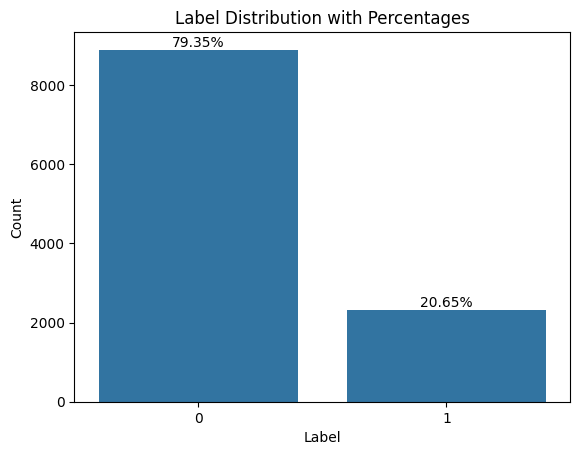

In [24]:
# Dataset Distribution

# Create count plot
ax = sns.countplot(x=df_combine.label)

# Get total number of samples
total = len(df_combine.label)

# Annotate percentages on bars
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.2f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom')

# Add title and labels
plt.title('Label Distribution with Percentages')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

In [25]:


# Word Count for news text

# Word Count
total_words = df_combine['text'].apply(lambda x: len(x.split())).sum()

# Character Count
total_characters = df_combine['text'].apply(len).sum()

# Sentence Count
total_sentences = df_combine['text'].apply(lambda x: len(sent_tokenize(x))).sum()

print(f"Word count for News: {total_words:,}")
print(f"Character count: {total_characters:,}")
print(f"Sentence count: {total_sentences:,}")

Word count for News: 1,849,904
Character count: 11,575,760
Sentence count: 16,284


**Word Map**

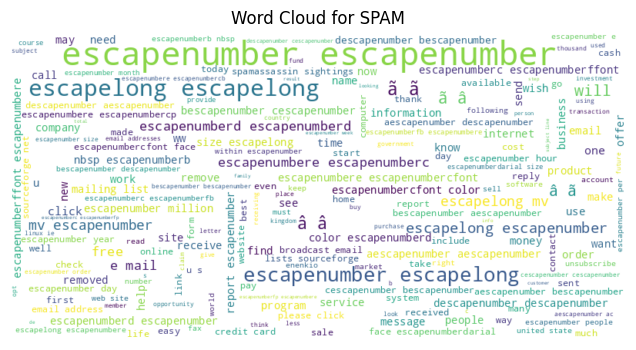

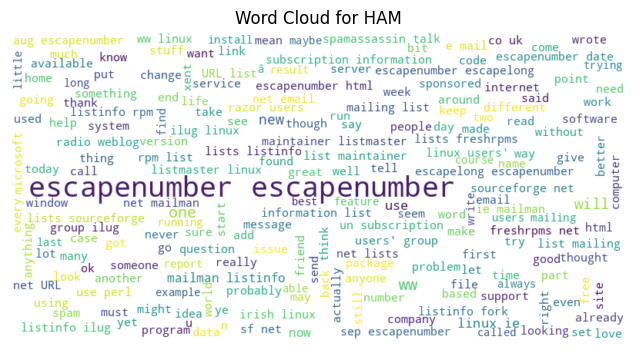

In [49]:


from wordcloud import WordCloud, STOPWORDS

stopwords = set(STOPWORDS)

# Create combined string for each class:  'FAKE': 1, 'REAL': 0
spam_text = " ".join(df_combine[df_combine['label'] == 1]['text'].tolist())
ham_text = " ".join(df_combine[df_combine['label'] == 0]['text'].tolist())

# Create WordClouds
fake_wc = WordCloud(width=800, height=400, background_color='white', stopwords=stopwords).generate(spam_text)
real_wc = WordCloud(width=800, height=400, background_color='white', stopwords=stopwords).generate(ham_text)

# Plot Fake News Word Cloud
plt.figure(figsize=(8,4))
plt.imshow(fake_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud for SPAM")
plt.show()

# Plot Real News Word Cloud
plt.figure(figsize=(8, 4))
plt.imshow(real_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud for HAM")
plt.show()

# **Parameterized Pipeline**

In [24]:


# Parametirized pipeline
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import optuna


# ============================================================
# 1. Select input features
# ============================================================

X_train = df_combine[['text']]
X_test = df_test[['text']]

y_train = df_combine[['label']]
y_test = df_test[['label']]


# Convert label DataFrames to 1D arrays
y_train = y_train.values.ravel()
y_test = y_test.values.ravel()


# ============================================================
# 2. Parameterized preprocessing pipeline
# ============================================================

def get_preprocessing_pipeline(
    max_features=None,
    vectorizer_type='tfidf',
    ngram_min=1,
    ngram_max=2,
    min_df=1
):

    # Select vectorizer
    if vectorizer_type == 'count':

        vectorizer = CountVectorizer(
            analyzer='char',
            max_features=max_features,
            ngram_range=(ngram_min, ngram_max),
            min_df=min_df,
            max_df=1.0
        )

    elif vectorizer_type == 'tfidf':

        vectorizer = TfidfVectorizer(
            analyzer='char',
            max_features=max_features,
            ngram_range=(ngram_min, ngram_max),
            min_df=min_df,
            max_df=1.0
        )

    else:
        raise ValueError(
            "vectorizer_type must be either 'count' or 'tfidf'"
        )

    # Pipeline
    pipeline = Pipeline([
        ('vectorizer', vectorizer)
    ])

    return pipeline

# **Logistic Regression**

In [ ]:

## Hyper Parameter Tuning for Logistic Regression

import optuna
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


# ============================================================
# Optuna Objective Function
# ============================================================

def objective(trial):

    # --------------------------------------------------------
    # 1. Logistic Regression hyperparameters
    # --------------------------------------------------------

    C = trial.suggest_float(
        "C",
        1e-3,
        5.0,
        log=True
    )

    max_iter = trial.suggest_int(
        "max_iter",
        100,
        2000
    )

    solver = trial.suggest_categorical(
        "solver",
        ["liblinear", "saga"]
    )

    penalty = trial.suggest_categorical(
        "penalty",
        ["l1", "l2"]
    )

    class_weight = trial.suggest_categorical(
        "class_weight",
        [None, "balanced"]
    )


    # --------------------------------------------------------
    # 2. Vectorizer hyperparameters
    # --------------------------------------------------------

    vectorizer_type = trial.suggest_categorical(
        "vectorizer_type",
        ["count", "tfidf"]
    )

    max_features = trial.suggest_int(
        "max_features",
        200000,
        500000
    )

    ngram_min = trial.suggest_int(
        "ngram_min",
        1,
        5
    )

    ngram_max = trial.suggest_int(
        "ngram_max",
        2,
        6
    )

    min_df = trial.suggest_int(
        "min_df",
        1,
        5
    )


    # --------------------------------------------------------
    # 3. Ensure valid n-gram range
    # --------------------------------------------------------

    if ngram_min > ngram_max:
        raise optuna.exceptions.TrialPruned()


    # --------------------------------------------------------
    # 4. Create preprocessing pipeline
    # --------------------------------------------------------

    pipeline_lr = get_preprocessing_pipeline(
        max_features=max_features,
        vectorizer_type=vectorizer_type,
        ngram_min=ngram_min,
        ngram_max=ngram_max,
        min_df=min_df
    )


    # --------------------------------------------------------
    # 5. Transform text data
    # --------------------------------------------------------

    X_train_transformed = pipeline_lr.fit_transform(
        X_train['text']
    )

    X_test_transformed = pipeline_lr.transform(
        X_test['text']
    )


    # --------------------------------------------------------
    # 6. Logistic Regression model
    # --------------------------------------------------------

    model = LogisticRegression(
        C=C,
        penalty=penalty,
        solver=solver,
        class_weight=class_weight,
        max_iter=max_iter,
        random_state=42
    )


    # --------------------------------------------------------
    # 7. Train model
    # --------------------------------------------------------

    model.fit(
        X_train_transformed,
        y_train
    )


    # --------------------------------------------------------
    # 8. Prediction
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test_transformed
    )


    # --------------------------------------------------------
    # 9. Evaluation
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    return accuracy


# ============================================================
# Run Optuna Optimization
# ============================================================

study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=30
)


# ============================================================
# Display Best Result
# ============================================================

print("\nBest Trial:")
print("Accuracy:", study.best_value)

print("\nBest Parameters:")

for key, value in study.best_params.items():
    print(f"  {key}: {value}")

[I 2026-09-19 03:17:00,768] A new study created in memory with name: no-name-d20949c7-ed26-4e31-95e2-5819de30ab3f
[I 2026-09-19 03:18:07,487] Trial 0 finished with value: 0.7101140978534133 and parameters: {'C': 0.0021111014144527484, 'max_iter': 404, 'solver': 'liblinear', 'penalty': 'l1', 'class_weight': None, 'vectorizer_type': 'tfidf', 'max_features': 361386, 'ngram_min': 1, 'ngram_max': 6, 'min_df': 5}. Best is trial 0 with value: 0.7101140978534133.
[I 2026-09-19 03:18:17,010] Trial 1 finished with value: 0.4237091471668923 and parameters: {'C': 0.009622915195046614, 'max_iter': 1936, 'solver': 'liblinear', 'penalty': 'l2', 'class_weight': 'balanced', 'vectorizer_type': 'tfidf', 'max_features': 461364, 'ngram_min': 1, 'ngram_max': 2, 'min_df': 4}. Best is trial 0 with value: 0.7101140978534133.
[I 2026-09-19 03:18:17,013] Trial 2 pruned. 
[I 2026-09-19 03:18:32,303] Trial 3 finished with value: 0.5534712821504545 and parameters: {'C': 0.2410376759106992, 'max_iter': 944, 'solver'

In [25]:

# ============================================================
# Logistic Regression
# Best Optuna Parameters
# ============================================================

best_C = 0.9995859933448458
best_max_iter = 2000
best_solver = "liblinear"
best_penalty = "l2"
best_class_weight = "balanced"

best_vectorizer_type = "tfidf"
best_max_features = 345397
best_ngram_min = 5
best_ngram_max = 5
best_min_df = 3


# ============================================================
# Character-Level Preprocessing Pipeline
# analyzer='char' is fixed inside the function
# ============================================================

pipeline_lr = get_preprocessing_pipeline(
    max_features=best_max_features,
    vectorizer_type=best_vectorizer_type,
    ngram_min=best_ngram_min,
    ngram_max=best_ngram_max,
    min_df=best_min_df
)


# ============================================================
# Transform Text
# ============================================================

X_train_transformed = pipeline_lr.fit_transform(
    X_train["text"]
)

X_test_transformed = pipeline_lr.transform(
    X_test["text"]
)


# ============================================================
# Final Logistic Regression Model
# ============================================================

modelLR = LogisticRegression(
    C=best_C,
    penalty=best_penalty,
    solver=best_solver,
    class_weight=best_class_weight,
    max_iter=best_max_iter,
    random_state=42
)


# ============================================================
# Train
# ============================================================

modelLR.fit(
    X_train_transformed,
    y_train
)


# ============================================================
# Prediction
# ============================================================

y_pred = modelLR.predict(
    X_test_transformed
)


# ============================================================
# Evaluation
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)


# ============================================================
# Results
# ============================================================

print("Logistic Regression")
print("Accuracy:", accuracy)
print("Macro F1:", f1)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred
    )
)

Logistic Regression
Accuracy: 0.7756720170179849
Macro F1: 0.6862145665543008

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.92      0.85      3672
           1       0.69      0.42      0.52      1499

    accuracy                           0.78      5171
   macro avg       0.74      0.67      0.69      5171
weighted avg       0.76      0.78      0.76      5171



# **Linear SVC**

In [34]:


## Hyper Parameter Tuning for LinearSVC

import optuna
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score


# ============================================================
# Optuna Objective Function
# ============================================================

def objective(trial):

    # --------------------------------------------------------
    # 1. LinearSVC hyperparameters
    # --------------------------------------------------------

    C = trial.suggest_float(
        "C",
        1e-3,
        10.0,
        log=True
    )

    max_iter = trial.suggest_int(
        "max_iter",
        100,
        2000
    )

    loss = trial.suggest_categorical(
        "loss",
        ["hinge", "squared_hinge"]
    )

    class_weight = trial.suggest_categorical(
        "class_weight",
        [None, "balanced"]
    )


    # --------------------------------------------------------
    # 2. Vectorizer hyperparameters
    # --------------------------------------------------------

    vectorizer_type = trial.suggest_categorical(
        "vectorizer_type",
        ["count", "tfidf"]
    )

    max_features = trial.suggest_int(
        "max_features",
        200000,
        500000
    )

    ngram_min = trial.suggest_int(
        "ngram_min",
        1,
        5
    )

    ngram_max = trial.suggest_int(
        "ngram_max",
        2,
        6
    )

    min_df = trial.suggest_int(
        "min_df",
        1,
        5
    )


    # --------------------------------------------------------
    # 3. Ensure valid n-gram range
    # --------------------------------------------------------

    if ngram_min > ngram_max:
        raise optuna.exceptions.TrialPruned()


    # --------------------------------------------------------
    # 4. Create preprocessing pipeline
    # --------------------------------------------------------

    pipeline_svc = get_preprocessing_pipeline(
        max_features=max_features,
        vectorizer_type=vectorizer_type,
        ngram_min=ngram_min,
        ngram_max=ngram_max,
        min_df=min_df
    )


    # --------------------------------------------------------
    # 5. Transform text data
    # --------------------------------------------------------

    X_train_transformed = pipeline_svc.fit_transform(
        X_train["text"]
    )

    X_test_transformed = pipeline_svc.transform(
        X_test["text"]
    )


    # --------------------------------------------------------
    # 6. LinearSVC model
    # --------------------------------------------------------

    model = LinearSVC(
        C=C,
        loss=loss,
        class_weight=class_weight,
        max_iter=max_iter,
        random_state=42
    )


    # --------------------------------------------------------
    # 7. Train model
    # --------------------------------------------------------

    model.fit(
        X_train_transformed,
        y_train
    )


    # --------------------------------------------------------
    # 8. Prediction
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test_transformed
    )


    # --------------------------------------------------------
    # 9. Evaluation
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    return accuracy


# ============================================================
# Run Optuna Optimization
# ============================================================

study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=30
)


# ============================================================
# Display Best Result
# ============================================================

print("\nBest Trial:")
print("Accuracy:", study.best_value)

print("\nBest Parameters:")

for key, value in study.best_params.items():
    print(f"  {key}: {value}")

[I 2026-09-17 05:36:05,911] A new study created in memory with name: no-name-10faa301-bba1-4af3-99b7-4e6a7a15c998
[I 2026-09-17 05:36:51,363] Trial 0 finished with value: 0.7464707019918778 and parameters: {'C': 0.0012204104821931499, 'max_iter': 1207, 'loss': 'squared_hinge', 'class_weight': 'balanced', 'vectorizer_type': 'tfidf', 'max_features': 332716, 'ngram_min': 3, 'ngram_max': 5, 'min_df': 1}. Best is trial 0 with value: 0.7464707019918778.
[I 2026-09-17 05:36:51,366] Trial 1 pruned. 
[I 2026-09-17 05:38:42,064] Trial 2 finished with value: 0.34016631212531423 and parameters: {'C': 0.13964706205318175, 'max_iter': 1608, 'loss': 'hinge', 'class_weight': 'balanced', 'vectorizer_type': 'count', 'max_features': 326995, 'ngram_min': 1, 'ngram_max': 6, 'min_df': 3}. Best is trial 0 with value: 0.7464707019918778.
[I 2026-09-17 05:38:49,353] Trial 3 finished with value: 0.4146199961322762 and parameters: {'C': 0.29448575549701866, 'max_iter': 1498, 'loss': 'squared_hinge', 'class_weigh


Best Trial:
Accuracy: 0.8039064010829626

Best Parameters:
  C: 8.942355851144505
  max_iter: 477
  loss: squared_hinge
  class_weight: balanced
  vectorizer_type: tfidf
  max_features: 200930
  ngram_min: 5
  ngram_max: 5
  min_df: 1


In [36]:

# ============================================================
# LinearSVC
# Best Optuna Parameters
# ============================================================

best_C = 8.942355851144505
best_max_iter = 477
best_loss = "squared_hinge"
best_penalty = "l2"
best_dual = True
best_class_weight = "balanced"

best_vectorizer_type = "tfidf"
best_max_features = 200930
best_ngram_min = 5
best_ngram_max = 5
best_min_df = 1


# ------------------------------------------------------------
# Text preprocessing
# ------------------------------------------------------------

pipeline_svc = get_preprocessing_pipeline(
    max_features=best_max_features,
    vectorizer_type=best_vectorizer_type,
    ngram_min=best_ngram_min,
    ngram_max=best_ngram_max,
    min_df=best_min_df
)


# ------------------------------------------------------------
# Transform train and test data
# ------------------------------------------------------------

X_train_transformed = pipeline_svc.fit_transform(
    X_train["text"]
)

X_test_transformed = pipeline_svc.transform(
    X_test["text"]
)


# ------------------------------------------------------------
# LinearSVC model
# ------------------------------------------------------------

modelSVC = LinearSVC(
    C=best_C,
    penalty=best_penalty,
    loss=best_loss,
    dual=best_dual,
    class_weight=best_class_weight,
    max_iter=best_max_iter,
    random_state=42
)


# ------------------------------------------------------------
# Train and predict
# ------------------------------------------------------------

modelSVC.fit(
    X_train_transformed,
    y_train
)

y_pred = modelSVC.predict(
    X_test_transformed
)


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("LinearSVC")
print("Accuracy:", accuracy)
print("Macro F1:", f1)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred
    )
)

LinearSVC
Accuracy: 0.8039064010829626
Macro F1: 0.7136608723802185

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.96      0.87      3672
           1       0.82      0.42      0.55      1499

    accuracy                           0.80      5171
   macro avg       0.81      0.69      0.71      5171
weighted avg       0.81      0.80      0.78      5171



# **SGD Classifier**

In [30]:

## Hyper Parameter Tuning for SGD Classifier

import optuna
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score


# ============================================================
# Optuna Objective Function
# ============================================================

def objective(trial):

    # --------------------------------------------------------
    # 1. SGD Classifier hyperparameters
    # --------------------------------------------------------

    alpha = trial.suggest_float(
        "alpha",
        1e-6,
        1e-2,
        log=True
    )

    max_iter = trial.suggest_int(
        "max_iter",
        100,
        2000
    )

    loss = trial.suggest_categorical(
        "loss",
        [
            "hinge",
            "log_loss",
            "modified_huber",
            "squared_hinge"
        ]
    )

    penalty = trial.suggest_categorical(
        "penalty",
        [
            "l2",
            "l1",
            "elasticnet"
        ]
    )

    learning_rate = trial.suggest_categorical(
        "learning_rate",
        [
            "optimal",
            "constant",
            "invscaling",
            "adaptive"
        ]
    )

    eta0 = trial.suggest_float(
        "eta0",
        1e-4,
        1e-1,
        log=True
    )

    class_weight = trial.suggest_categorical(
        "class_weight",
        [
            None,
            "balanced"
        ]
    )


    # --------------------------------------------------------
    # 2. Vectorizer hyperparameters
    # --------------------------------------------------------

    vectorizer_type = trial.suggest_categorical(
        "vectorizer_type",
        [
            "count",
            "tfidf"
        ]
    )

    max_features = trial.suggest_int(
        "max_features",
        200000,
        500000
    )

    ngram_min = trial.suggest_int(
        "ngram_min",
        1,
        5
    )

    ngram_max = trial.suggest_int(
        "ngram_max",
        2,
        6
    )

    min_df = trial.suggest_int(
        "min_df",
        1,
        5
    )


    # --------------------------------------------------------
    # 3. Ensure valid n-gram range
    # --------------------------------------------------------

    if ngram_min > ngram_max:
        raise optuna.exceptions.TrialPruned()


    # --------------------------------------------------------
    # 4. Create preprocessing pipeline
    # --------------------------------------------------------

    pipeline_sgd = get_preprocessing_pipeline(
        max_features=max_features,
        vectorizer_type=vectorizer_type,
        ngram_min=ngram_min,
        ngram_max=ngram_max,
        min_df=min_df
    )


    # --------------------------------------------------------
    # 5. Transform text data
    # --------------------------------------------------------

    X_train_transformed = pipeline_sgd.fit_transform(
        X_train["text"]
    )

    X_test_transformed = pipeline_sgd.transform(
        X_test["text"]
    )


    # --------------------------------------------------------
    # 6. SGD Classifier
    # --------------------------------------------------------

    model = SGDClassifier(
        alpha=alpha,
        max_iter=max_iter,
        loss=loss,
        penalty=penalty,
        learning_rate=learning_rate,
        eta0=eta0,
        class_weight=class_weight,
        random_state=42
    )


    # --------------------------------------------------------
    # 7. Train model
    # --------------------------------------------------------

    model.fit(
        X_train_transformed,
        y_train
    )


    # --------------------------------------------------------
    # 8. Prediction
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test_transformed
    )


    # --------------------------------------------------------
    # 9. Evaluation
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    return accuracy


# ============================================================
# Run Optuna Optimization
# ============================================================

study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=30
)


# ============================================================
# Display Best Result
# ============================================================

print("\nBest Trial:")
print("Accuracy:", study.best_value)

print("\nBest Parameters:")

for key, value in study.best_params.items():
    print(f"  {key}: {value}")

[I 2026-09-13 15:17:35,239] A new study created in memory with name: no-name-c8efeda1-4f92-495b-a96e-697b5e57e045
[I 2026-09-13 15:18:00,244] Trial 0 finished with value: 0.7464707019918778 and parameters: {'alpha': 0.0036946834536443016, 'max_iter': 1938, 'loss': 'modified_huber', 'penalty': 'l2', 'learning_rate': 'optimal', 'eta0': 0.0070740825182885264, 'class_weight': None, 'vectorizer_type': 'count', 'max_features': 245358, 'ngram_min': 5, 'ngram_max': 6, 'min_df': 4}. Best is trial 0 with value: 0.7464707019918778.
[I 2026-09-13 15:18:14,278] Trial 1 finished with value: 0.6559659640301683 and parameters: {'alpha': 0.002642280653440348, 'max_iter': 177, 'loss': 'hinge', 'penalty': 'l1', 'learning_rate': 'adaptive', 'eta0': 0.00010822209093013897, 'class_weight': 'balanced', 'vectorizer_type': 'count', 'max_features': 340425, 'ngram_min': 2, 'ngram_max': 3, 'min_df': 4}. Best is trial 0 with value: 0.7464707019918778.
[I 2026-09-13 15:18:35,461] Trial 2 finished with value: 0.3879


Best Trial:
Accuracy: 0.8015857667762522

Best Parameters:
  alpha: 2.3559351570101205e-06
  max_iter: 452
  loss: squared_hinge
  penalty: elasticnet
  learning_rate: adaptive
  eta0: 0.09868310103895356
  class_weight: None
  vectorizer_type: tfidf
  max_features: 411328
  ngram_min: 4
  ngram_max: 6
  min_df: 1


In [31]:

# SGD Classifier
# Best Optuna parameters
best_alpha = 2.3559351570101205e-06
best_max_iter = 452
best_loss = "squared_hinge"
best_penalty = "elasticnet"
best_learning_rate = "adaptive"
best_eta0 = 0.09868310103895356
best_class_weight = None
best_vectorizer_type = "tfidf"
best_max_features = 411328
best_ngram_min = 4
best_ngram_max = 6
best_min_df = 1


# Parameterized character-level preprocessing pipeline
pipeline_sgd = get_preprocessing_pipeline(
    max_features=best_max_features,
    vectorizer_type=best_vectorizer_type,
    ngram_min=best_ngram_min,
    ngram_max=best_ngram_max,
    min_df=best_min_df
)


# Transform text
X_train_transformed = pipeline_sgd.fit_transform(
    X_train["text"]
)

X_test_transformed = pipeline_sgd.transform(
    X_test["text"]
)


# Final SGD Classifier
modelSGD = SGDClassifier(
    alpha=best_alpha,
    max_iter=best_max_iter,
    loss=best_loss,
    penalty=best_penalty,
    learning_rate=best_learning_rate,
    eta0=best_eta0,
    class_weight=best_class_weight,
    random_state=42
)


# Train
modelSGD.fit(
    X_train_transformed,
    y_train
)


# Prediction
y_pred = modelSGD.predict(
    X_test_transformed
)


# Evaluation
accuracy = accuracy_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("SGD Classifier")
print("Accuracy:", accuracy)
print("Macro F1:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

SGD Classifier
Accuracy: 0.8015857667762522
Macro F1: 0.7200227340370964

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.94      0.87      3672
           1       0.77      0.45      0.57      1499

    accuracy                           0.80      5171
   macro avg       0.79      0.70      0.72      5171
weighted avg       0.80      0.80      0.78      5171

